# **01 - Introduction**
# Restaurant Tips Analysis and Prediction

## Project Overview

This project explores restaurant customer tipping behavior using exploratory data analysis, statistical hypothesis testing, and machine learning.

The objective is to identify the factors associated with tip amounts and develop predictive models to estimate tips based on transaction and customer characteristics.

## Project Objectives

- Explore customer tipping patterns and transaction characteristics.
- Identify relationships between total bill amounts, table size, and tip amounts.
- Investigate whether tipping behavior differs across customer groups and dining periods.
- Apply statistical tests to evaluate observed differences.
- Develop and compare machine learning regression models to predict tip amounts.

## Dataset Overview

- **Observations:** 244
- **Variables:** 7
- **Target variable:** `tip`

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- SciPy
- Scikit-learn

## Project Workflow

1. Data Understanding
2. Data Quality Assessment and Cleaning
3. Exploratory Data Analysis
4. Statistical Analysis
5. Feature Engineering and Preprocessing
6. Machine Learning Model Development
7. Model Evaluation and Comparison
8. Conclusions and Recommendations

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# **02 - Data Understanding**

In [111]:
df = pd.read_csv('/content/drive/MyDrive/data projects/tips.csv')
#df = pd.read_csv('../data/tips.csv')



#Dataset overview
print('Dataset shape: ', df.shape)
display(df.head())

print('\nDataset information:')
df.info()

Dataset shape:  (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


In [112]:
variable_desription = {
    'total_bill': 'total bill in $ + taxes',
    'tip': 'tip in $',
    'sex': 'gender of the person paying the bill',
    'smoker': 'smoking status',
    'day': 'day of the week',
    'time': 'lunch or dinner',
    'size': 'number of people at the table'
    }

variable_df = pd.DataFrame(variable_desription.items(),
                             columns = ['Variable', 'Description'])
display(variable_df)

,Variable,Description
0,total_bill,total bill in $ + taxes
1,tip,tip in $
2,sex,gender of the person paying the bill
3,smoker,smoking status
4,day,day of the week
5,time,lunch or dinner
6,size,number of people at the table


In [113]:
#any missing values
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing %':  (df.isnull().mean()*100).round(2)
})
display(missing_summary)

# Check duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

,Missing Values,Missing %
total_bill,0,0.0
tip,0,0.0
sex,0,0.0
smoker,0,0.0
day,0,0.0
time,0,0.0
size,0,0.0


Number of duplicate rows: 1


In [114]:
df[df.duplicated()]

,total_bill,tip,sex,smoker,day,time,size
202,13.0,2.0,Female,Yes,Thur,Lunch,2


In [115]:
# Numerical variables

display(df.describe().T.round(2))

# Categorical variables

display(df.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.79,8.90,3.07,13.35,17.8,24.13,50.81
tip,244.0,3.00,1.38,1.00,2.00,2.9,3.56,10.00
size,244.0,2.57,0.95,1.00,2.00,2.0,3.00,6.00


,count,unique,top,freq
sex,244,2,Male,157
smoker,244,2,No,151
day,244,4,Sat,87
time,244,2,Dinner,176


In [116]:
#checking variable uniqueness
for col in df.select_dtypes(include = 'object').columns:
  print(f'\n{col}: {df[col].value_counts()}')


sex: sex
Male      157
Female     87
Name: count, dtype: int64

smoker: smoker
No     151
Yes     93
Name: count, dtype: int64

day: day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

time: time
Dinner    176
Lunch      68
Name: count, dtype: int64


### Key Observations

- The dataset contains 244 observations and 7 variables.
- No missing values were identified.
- One exact duplicate row was identified. It was retained because identical records may represent separate transactions, and the available data does not establish whether it is an erroneous duplicate.
- The average total bill is approximately $19.79, while the average tip is approximately $3.00.
- The dataset includes both numerical and categorical variables, allowing for different types of exploratory and statistical analysis.


# **03 - Data Quality Assesment and  Cleaning**



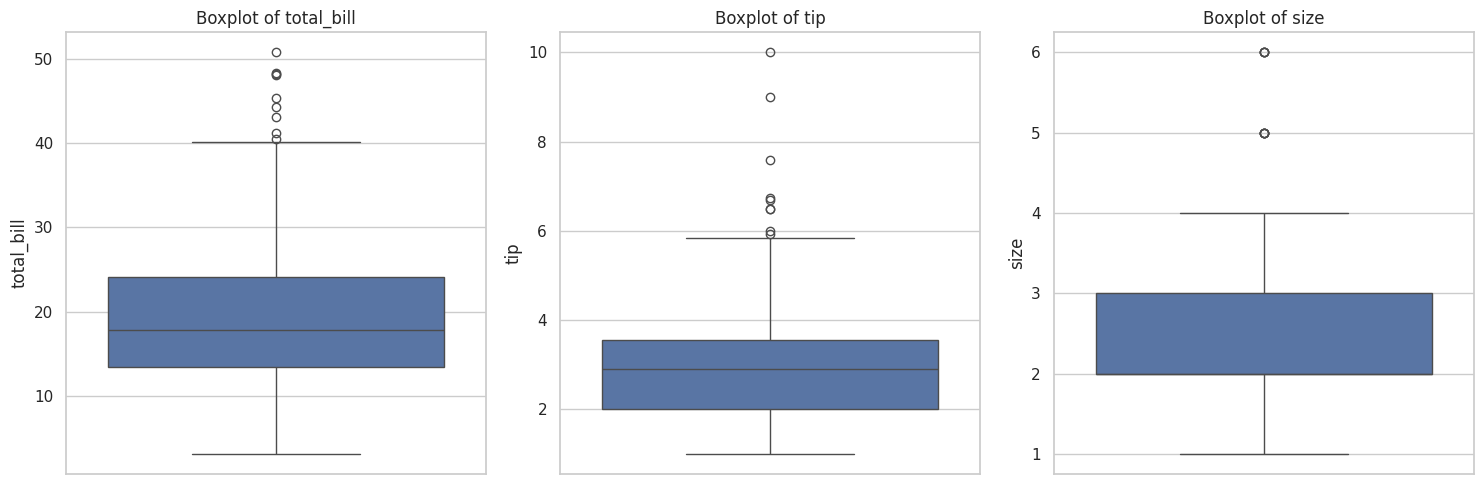

In [117]:
fig, axes = plt.subplots(1,3, figsize = (15,5))

for ax, col in zip(axes, ['total_bill', 'tip', 'size']):
  sns.boxplot(data = df, y=col, ax=ax)
  ax.set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

Outliers in numerical variables were investigated using boxplots and the Interquartile Range (IQR) method.

The IQR method identifies potential outliers as observations below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.

The analysis focuses on total_bill, tip, and size.

In [118]:
#identifying outliers

num_cols = list(df.select_dtypes(include = ['int64', 'float64']).columns)
print(num_cols)

for col in num_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3-Q1

  lower = Q1 - 1.5 *IQR
  upper = Q3 + 1.5*IQR

  outliers = df[
      (df[col]< lower) | (df[col]> upper )
  ]
  print(f'\nVariable: {col}')
  print('Lower bound: ', round(lower,2))
  print('Upper bound: ', round(upper,2))
  print('Number of outliers: ',len(outliers))

['total_bill', 'tip', 'size']

Variable: total_bill
Lower bound:  -2.82
Upper bound:  40.3
Number of outliers:  9

Variable: tip
Lower bound:  -0.34
Upper bound:  5.91
Number of outliers:  9

Variable: size
Lower bound:  0.5
Upper bound:  4.5
Number of outliers:  9


In [119]:
#checking numerical data validity

print('Zero or negative total bills:')
print((df['total_bill']<= 0).sum())

print('Zero or negative tips:')
print((df['tip']<= 0).sum())

print('Invalid table size:')
print((df['size']<= 0).sum())

Zero or negative total bills:
0
Zero or negative tips:
0
Invalid table size:
0


### Data Quality Assessment — Summary

- No missing values were detected.
- One exact duplicate row was identified and retained for further analysis.
- Potential outliers were detected in numerical variables using the IQR method.
- All identified outliers were retained because they may represent legitimate customer transactions.
- No zero or negative values were identified in the numerical variables checked.

No observations were removed during this stage.

# **04 - EDA**

##4.1 Univariate analysis


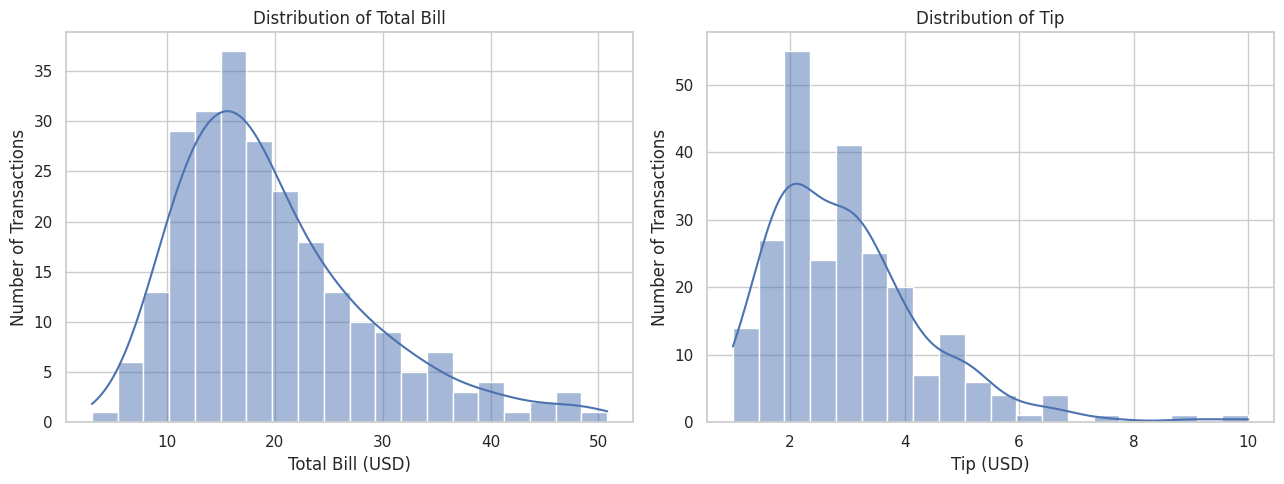

In [120]:
# Distribution of continuous numerical variables

continuous_cols = ['total_bill', 'tip']

sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(axes, continuous_cols):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=20,
        ax=ax
    )

    ax.set_title(f'Distribution of {col.replace("_", " ").title()}')
    ax.set_xlabel(f'{col.replace("_", " ").title()} (USD)')
    ax.set_ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

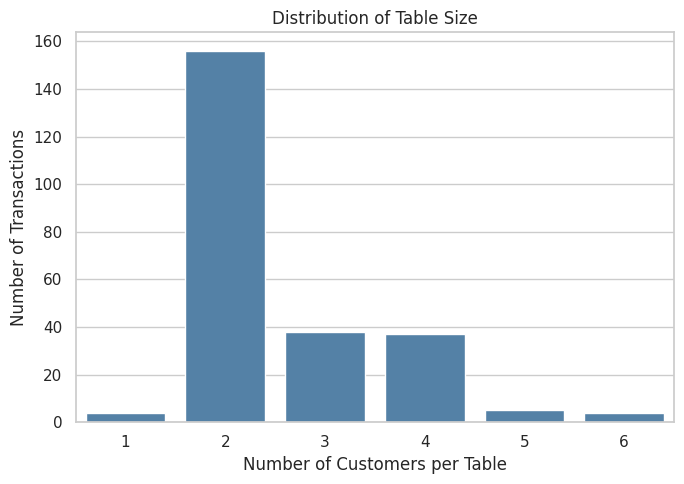

In [121]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='size',
    color='steelblue'
)

plt.title('Distribution of Table Size')
plt.xlabel('Number of Customers per Table')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

### Key Observations — Numerical Distributions

- **Total Bill:** The distribution is right-skewed, indicating that most transactions have relatively moderate bill amounts, while a smaller number of transactions have higher bills.
- **Tip:** Tip amounts are also right-skewed, with most tips concentrated around the lower-to-middle range.
- **Table Size:** Most transactions involve two customers, followed by groups of three and four.

These distributions indicate that the dataset contains relatively few large transactions and larger dining groups.

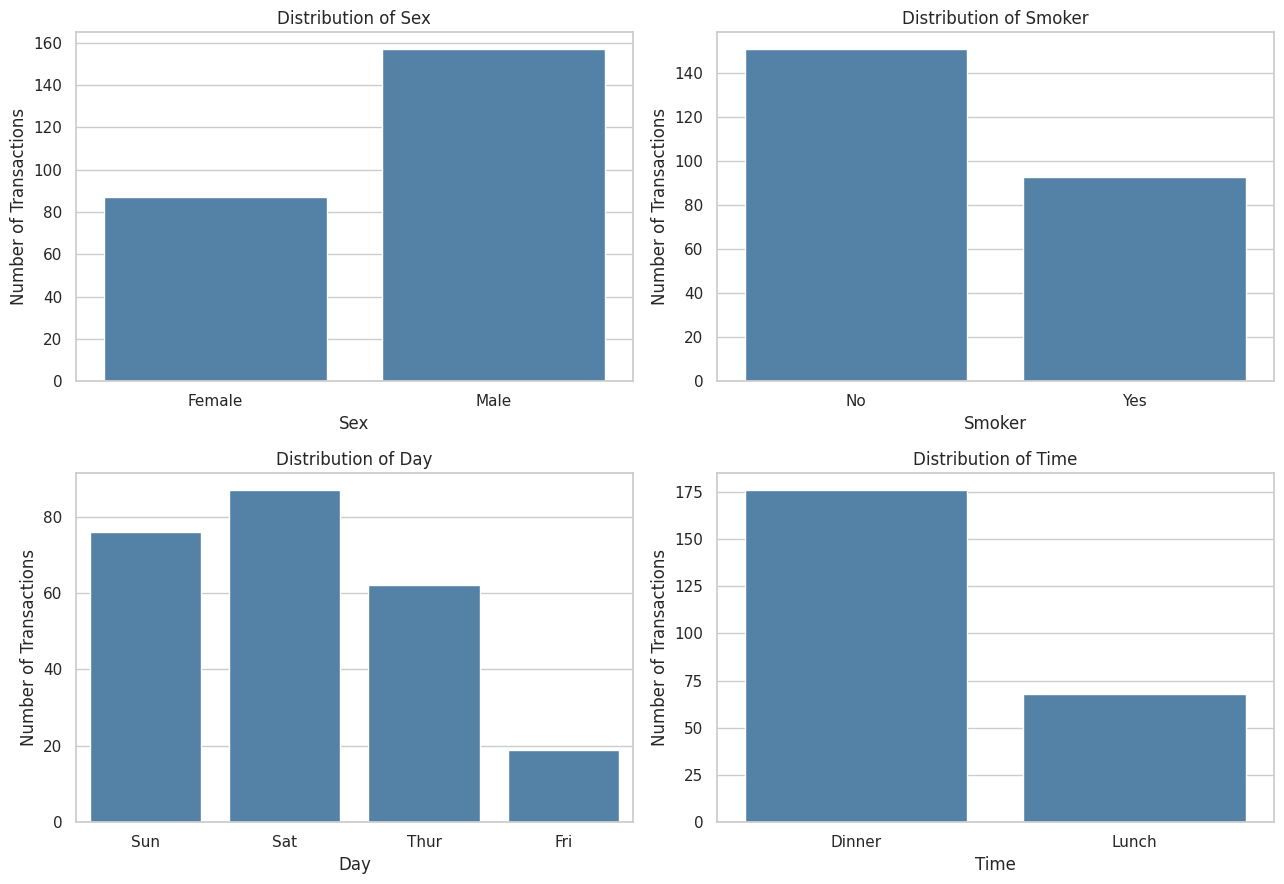

In [122]:
# Distribution of categorical variables

cat_cols = list(df.select_dtypes(include = 'object').columns)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), cat_cols):

    sns.countplot(
        data=df,
        x=col,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(f'Distribution of {col.title()}')
    ax.set_xlabel(col.title())
    ax.set_ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

### Key Observations — Categorical Distributions

- **Gender:** Male customers account for a larger share of observations.
- **Smoking Status:** Non-smokers represent a slightly larger share of the dataset.
- **Day:** Saturday has the highest number of recorded transactions.
- **Dining Time:** Dinner transactions are substantially more frequent than lunch transactions.

The dataset is not evenly distributed across customer characteristics and dining periods. This should be considered when interpreting group comparisons.

## 4.2 Bivariate analysis

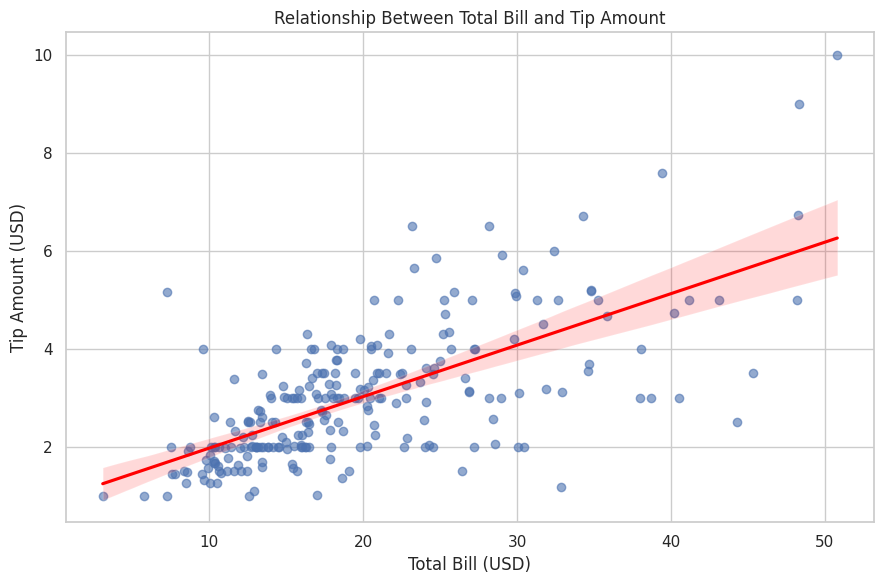

Pearson correlation: 0.676


In [123]:
#Does a higher bill correspond to a higher tip?
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x='total_bill',
    y='tip',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between Total Bill and Tip Amount')
plt.xlabel('Total Bill (USD)')
plt.ylabel('Tip Amount (USD)')

plt.tight_layout()
plt.show()

correlation = df['total_bill'].corr(df['tip'])

print(f'Pearson correlation: {correlation:.3f}')

### Finding 1 — Total Bill and Tip

A moderately strong positive relationship exists between total bill amount and tip amount.

Customers with higher bills generally leave larger tips. This suggests that transaction size is an important factor associated with tipping behavior.

However, correlation does not establish causation.

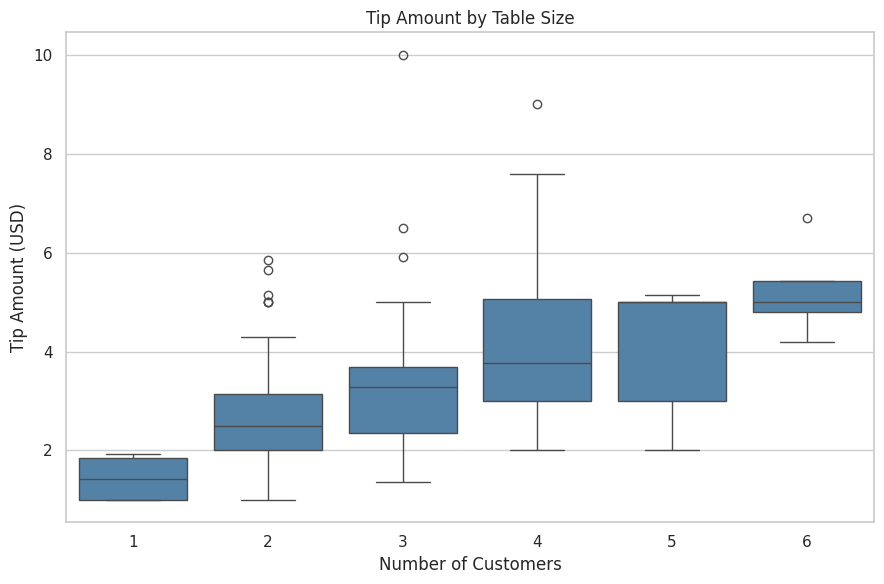

,count,mean,median
size,,,
1,4,1.44,1.42
2,156,2.58,2.50
3,38,3.39,3.29
4,37,4.14,3.76
5,5,4.03,5.00
6,4,5.22,5.00


In [124]:
#Does table size influence tip amounts?
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='size',
    y='tip',
    color='steelblue'
)

plt.title('Tip Amount by Table Size')
plt.xlabel('Number of Customers')
plt.ylabel('Tip Amount (USD)')

plt.tight_layout()
plt.show()

display(
    df.groupby('size')['tip']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

In [125]:
df['tip_percentage'] = (df['tip']/df['total_bill'])*100

df.groupby('size')['tip_percentage'].agg(
    ['count', 'mean', 'median']
).round(2)

,count,mean,median
size,,,
1,4,21.73,20.28
2,156,16.57,15.61
3,38,15.22,15.93
4,37,14.59,14.67
5,5,14.15,12.14
6,4,15.62,16.29


###Finding 2: Table Size and Tip
* table size and tip amount has moderate positive association
* mean and median tip amounts generally increases as table size increases
* larger tables tend to leave higher absolute tips, but their average tip percentage is generally lower in this dataset.

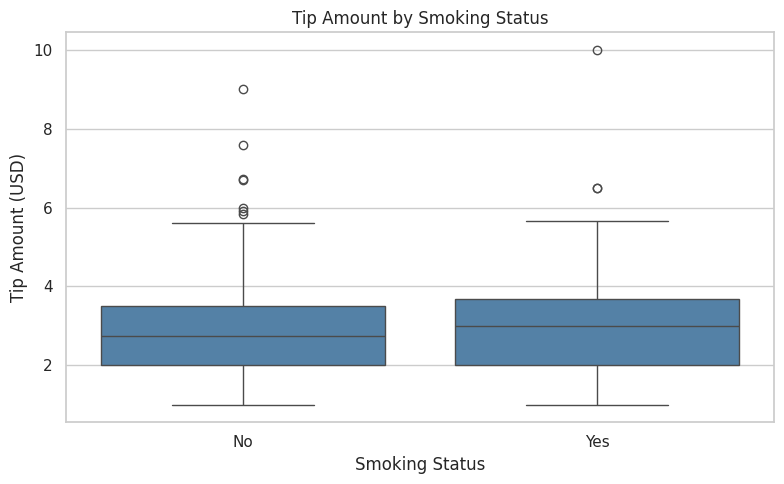

,count,mean,median
smoker,,,
No,151,2.99,2.74
Yes,93,3.01,3.00


In [126]:
#Do smokers and non-smokers tip differently?
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='smoker',
    y='tip',
    color='steelblue'
)

plt.title('Tip Amount by Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Tip Amount (USD)')

plt.tight_layout()
plt.show()

display(
    df.groupby('smoker')['tip']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

### Finding 3 — Smoking Status and Tip Amount

The tip distributions of smokers and non-smokers overlap considerably.

There is no strong visual evidence of a substantial difference in tipping behavior between the two groups.

Smoking status alone may therefore provide limited predictive information about tip amounts.


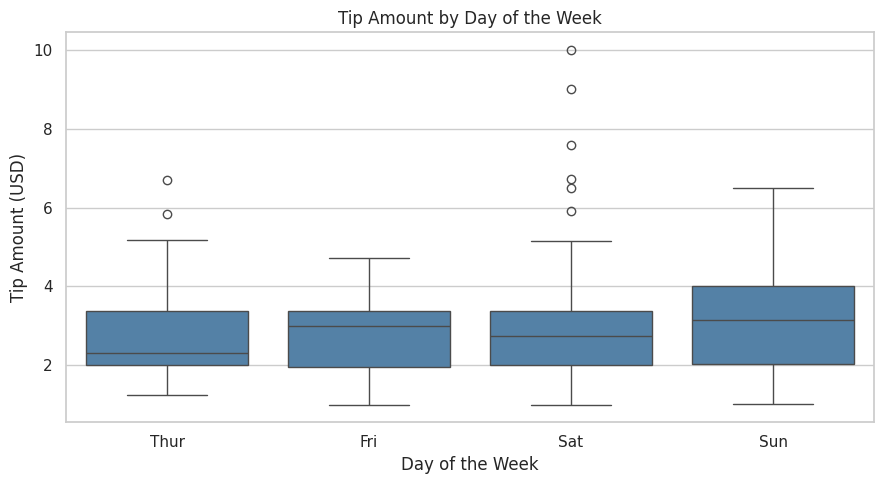

,count,mean,median
day,,,
Thur,62,2.77,2.30
Fri,19,2.73,3.00
Sat,87,2.99,2.75
Sun,76,3.26,3.15


In [127]:
#Does the day of the week matter?
day_order = ['Thur', 'Fri', 'Sat', 'Sun']

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='day',
    y='tip',
    order=day_order,
    color='steelblue'
)

plt.title('Tip Amount by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Tip Amount (USD)')

plt.tight_layout()
plt.show()

display(
    df.groupby('day')['tip']
    .agg(['count', 'mean', 'median'])
    .reindex(day_order)
    .round(2)
)

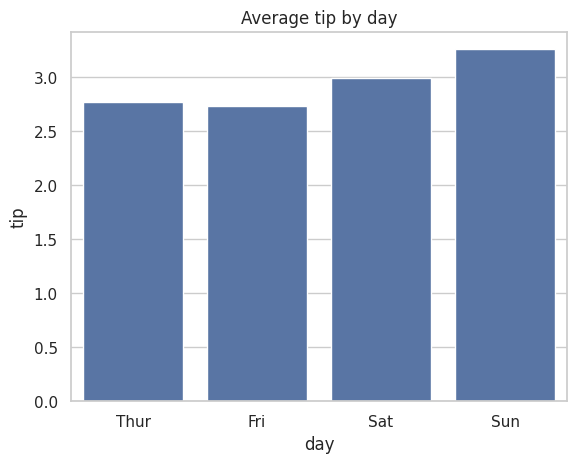

In [128]:
#average tips

sns.barplot(
    data = df, x='day', y='tip',
    order = ['Thur', 'Fri', 'Sat', 'Sun'],
    errorbar = None
)
plt.title('Average tip by day')
plt.show()

Observation:
Sunday has the highest average tip amount, while Friday has the lowest. However, the differences are relatively small, and the distributions overlap. Therefore, the day of the week may provide some predictive information, but its importance should be evaluated alongside other transaction characteristics.

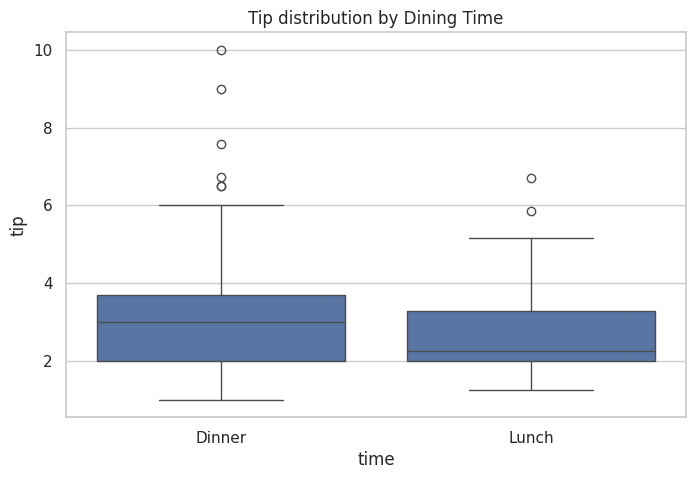

,count,mean,median,std
time,,,,
Dinner,176,3.10,3.00,1.44
Lunch,68,2.73,2.25,1.21


In [129]:
#Do customers tip more during dinner or lunch?

plt.figure(figsize = (8,5))

sns.boxplot(
    data = df, x='time', y= 'tip'
)
plt.title('Tip distribution by Dining Time')
plt.show()

df.groupby('time')['tip'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

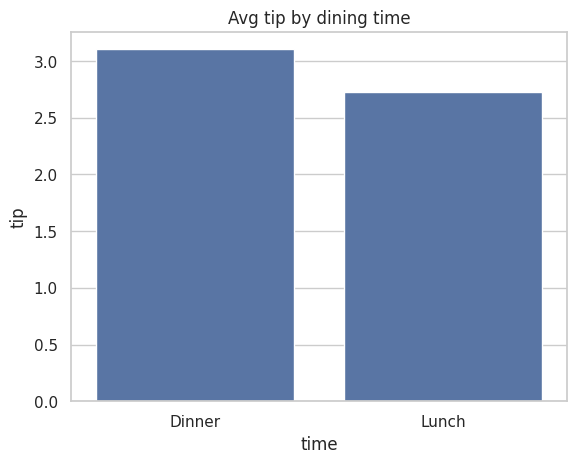

In [130]:
sns.barplot(
    data = df, x='time', y ='tip', errorbar=None
)
plt.title('Avg tip by dining time')
plt.show()

Dinner customers tend to leave higher absolute tips, but this may partly reflect larger bills.

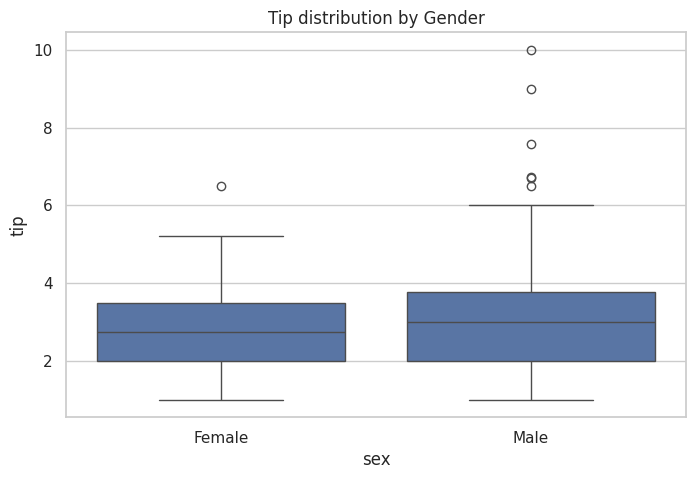

        count  mean  median   std
sex                              
Female     87  2.83    2.75  1.16
Male      157  3.09    3.00  1.49


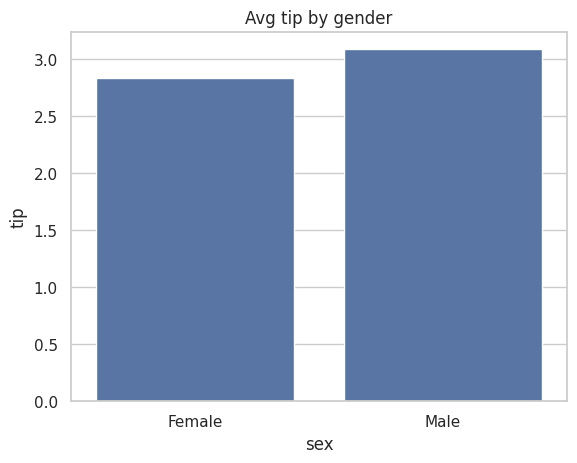

In [131]:
# male vs female

plt.figure(figsize = (8,5))

sns.boxplot(
    data = df, x='sex', y= 'tip'
)
plt.title('Tip distribution by Gender')
plt.show()

print(df.groupby('sex')['tip'].agg(
    ['count', 'mean', 'median', 'std']
).round(2))

sns.barplot(
    data = df, x='sex', y ='tip', errorbar=None
)
plt.title('Avg tip by gender')
plt.show()

Male customers have slightly higher average tips in this sample, but gender alone may not be a strong predictor.

## 4.3 Multivariate analysis


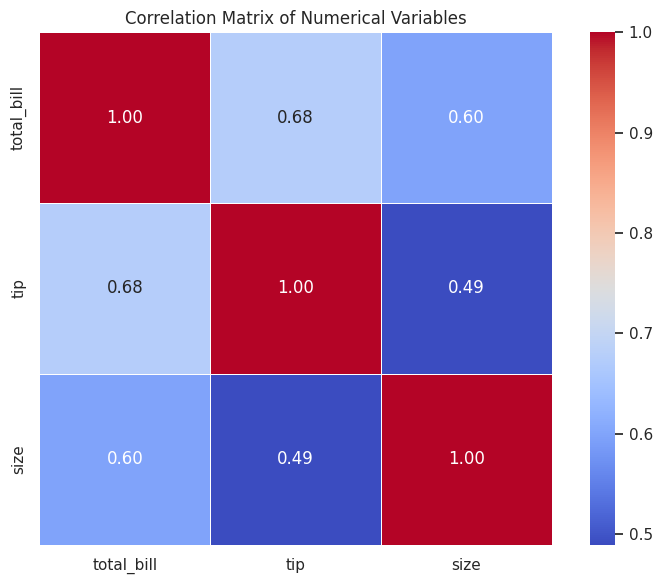

In [132]:
# Correlation between numerical variables

numeric_cols = ['total_bill', 'tip', 'size']

corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Matrix of Numerical Variables')

plt.tight_layout()
plt.show()

observation:
* total bill has the strongest linear relationship with tip
* total bill and table size are moderately correlated ==> may contain overlapping predictive information

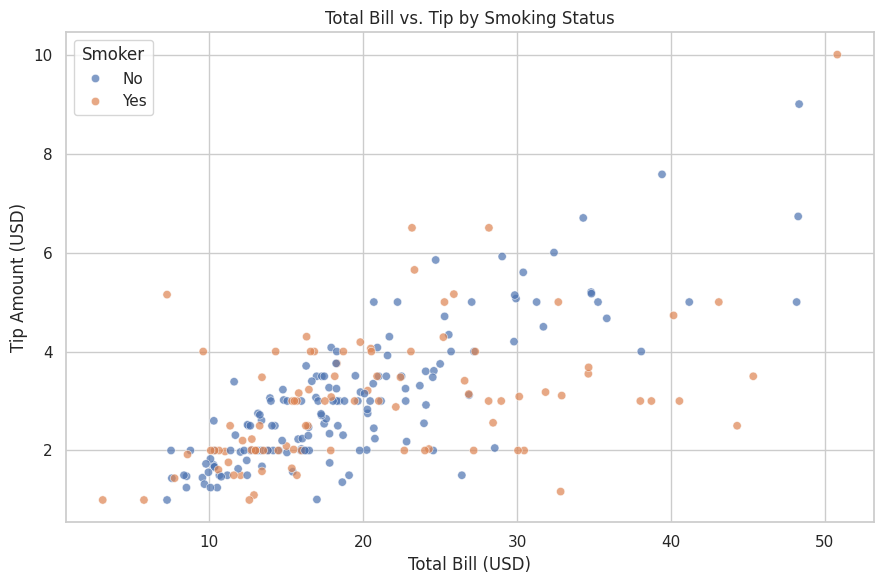

In [133]:
#Total bill vs. tip by smoking status
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='total_bill',
    y='tip',
    hue='smoker',
    alpha=0.7
)

plt.title('Total Bill vs. Tip by Smoking Status')
plt.xlabel('Total Bill (USD)')
plt.ylabel('Tip Amount (USD)')
plt.legend(title='Smoker')

plt.tight_layout()
plt.show()

no obvious separation between smoker and non smokers

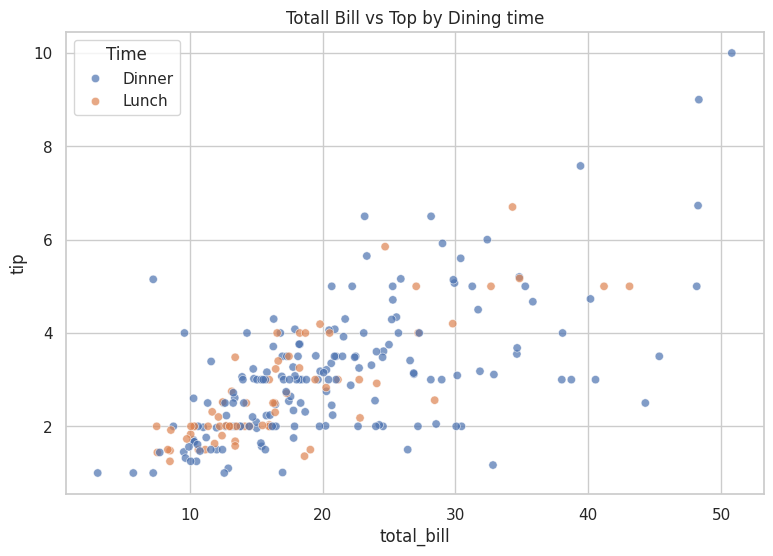

In [134]:
#total bill vs tip by dining time

plt.figure(figsize = (9,6))
sns.scatterplot(
    data = df, x='total_bill', y='tip',
    hue = 'time', alpha = 0.7
)
plt.title('Totall Bill vs Top by Dining time')
plt.legend(title = 'Time')

plt.show()

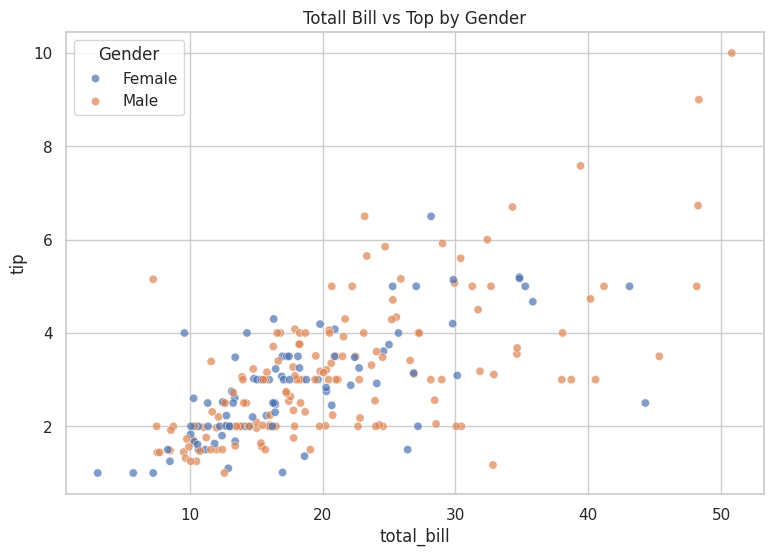

In [135]:
#total bill vs tip by gender

plt.figure(figsize = (9,6))
sns.scatterplot(
    data = df, x='total_bill', y='tip',
    hue = 'sex', alpha = 0.7
)
plt.title('Totall Bill vs Top by Gender')
plt.legend(title = 'Gender')

plt.show()

both genders exhibit a positive relationship between total bill and tip
male customers appear more frequently among high tips and total bill


## EDA — Summary of Key Findings

The exploratory data analysis identified several patterns in restaurant tipping behavior:

1. **Transaction size:** Total bill amount has the strongest positive association with tip amount.
2. **Table size:** Larger tables generally leave higher absolute tips, although tip percentages tend to decrease as table size increases.
3. **Smoking status:** No substantial visual differences were observed between smokers and non-smokers.
4. **Day of the week:** Sunday recorded the highest average tip, while Friday recorded the lowest.
5. **Dining period:** Dinner transactions generally have higher absolute tip amounts than lunch transactions.
6. **Customer gender:** Male customers recorded slightly higher average tips in this sample.

Overall, transaction-related characteristics appear more informative than individual customer characteristics when examining tipping behavior.

The next section uses statistical hypothesis testing to determine whether selected observed relationships and group differences are statistically significant.

#**05 - Statistical analysis**

## 5.1 Correlation Analysis

In [136]:
from scipy.stats import pearsonr

# Pearson correlation analysis

correlation_pairs = [
    ('total_bill', 'tip'),
    ('size', 'tip')
]

for x, y in correlation_pairs:

    corr, p_value = pearsonr(df[x], df[y])

    print(f'\n{x} vs. {y}')
    print(f'Pearson correlation: {corr:.3f}')
    print(f'P-value: {p_value:.4e}')

    if p_value < 0.05:
        print('Result: Statistically significant correlation')
    else:
        print('Result: No statistically significant correlation')


total_bill vs. tip
Pearson correlation: 0.676
P-value: 6.6925e-34
Result: Statistically significant correlation

size vs. tip
Pearson correlation: 0.489
P-value: 4.3005e-16
Result: Statistically significant correlation


##5.2 Independent samples t-test

In [137]:

#do smokers and non-smokers leave significantly different average tip amounts?
#H0: average tip smoke = avg tip non smoker

from scipy.stats import ttest_ind

# Separate groups

smokers = df[df['smoker'] == 'Yes']['tip']
non_smokers = df[df['smoker'] == 'No']['tip']

# Welch's independent samples t-test

t_stat, p_value = ttest_ind(
    smokers,
    non_smokers,
    equal_var=False
)

print(f'Smokers mean tip: ${smokers.mean():.3f}')
print(f'Non-smokers mean tip: ${non_smokers.mean():.3f}')
print(f'T-statistic: {t_stat:.4f}')
print(f'P-value: {p_value:.4f}')

Smokers mean tip: $3.009
Non-smokers mean tip: $2.992
T-statistic: 0.0918
P-value: 0.9269


The Welch's independent samples t-test produced a p-value of 0.9269, which is greater than the 0.05 significance level.

Therefore, we fail to reject the null hypothesis.

There is insufficient statistical evidence to conclude that average tip amounts differ between smokers and non-smokers in this dataset.

Although the observed average tip for smokers is slightly higher, the difference is very small and statistically insignificant.


##5.3 One-way ANOVA

In [138]:
#one way ANOVA
#H0: mean tips are equal across all four days of the week
#H1: at least one day-s mean tip differs

from scipy.stats import f_oneway

day_order = ['Thur', 'Fri', 'Sat', 'Sun']

groups = [
    df[df['day'] == day]['tip']
    for day in day_order
]

# One-way ANOVA

f_stat, p_value = f_oneway(*groups)

print(f'F-statistic: {f_stat:.4f}')
print(f'P-value: {p_value:.4f}')

print('\nAverage tip by day:')

display(
    df.groupby('day')['tip']
    .agg(['count', 'mean', 'median'])
    .reindex(day_order)
    .round(3)
)

F-statistic: 1.6724
P-value: 0.1736

Average tip by day:


,count,mean,median
day,,,
Thur,62,2.771,2.305
Fri,19,2.735,3.000
Sat,87,2.993,2.750
Sun,76,3.255,3.150


The one-way ANOVA produced a p-value of 0.1736, which is greater than the 0.05 significance level.

Therefore, we fail to reject the null hypothesis.

Although Sunday has the highest observed average tip and Friday has the lowest, there is insufficient statistical evidence to conclude that mean tip amounts differ across the four days of the week using the ANOVA test.

In [139]:
#Testing anova assumptions
#1: normality of residuals: shapiro wilk test
#2: homogeneity of variances: levene test

from scipy.stats import shapiro, levene
groups = [
    df[df['day']== day ]['tip']
    for day in df['day'].unique()
]

for day in df['day'].unique():
  stat, p = shapiro(df[df['day']==day]['tip'])
  print(f'{day}: Shapiro p value = {p:.4f}')

stat, p = levene(*groups)
print('\nLevene statistic:', stat)
print('Levene p-value:', p)

Sun: Shapiro p value = 0.0263
Sat: Shapiro p value = 0.0000
Thur: Shapiro p value = 0.0000
Fri: Shapiro p value = 0.8497

Levene statistic: 0.5519761112415968
Levene p-value: 0.6472822314837223


The Shapiro-Wilk test on ANOVA residuals is used to assess the normality assumption.

The previous group-level Shapiro-Wilk tests indicated departures from normality for three of the four days.

Levene's test produced a p-value of 0.6473, providing no significant evidence of unequal variances.

Since the normality assumption is questionable, a non-parametric Kruskal-Wallis test is additionally applied to examine differences in tip distributions across the four days.

In [140]:
#Kruskal-Wallis test
from scipy.stats import kruskal

groups = [
    df[df['day'] == day]['tip']
    for day in df['day'].unique()
]

h_stat, p_value = kruskal(*groups)

print('Kruskal-Wallis H statistic:', h_stat)
print('P-value:', p_value)

Kruskal-Wallis H statistic: 8.565587588927054
P-value: 0.035660560194476144


The Kruskal-Wallis test produced a p-value of 0.0357 < 0.05 significance level.

Therefore, we reject the null hypothesis of identical tip distributions across the four days.

This suggests that at least one day's tip distribution differs from the others.

Unlike ANOVA, the Kruskal-Wallis test evaluates differences in rank distributions. It should not automatically be interpreted as evidence of different medians unless the group distributions have similar shapes.

A post-hoc pairwise comparison would be required to identify which specific days differ.

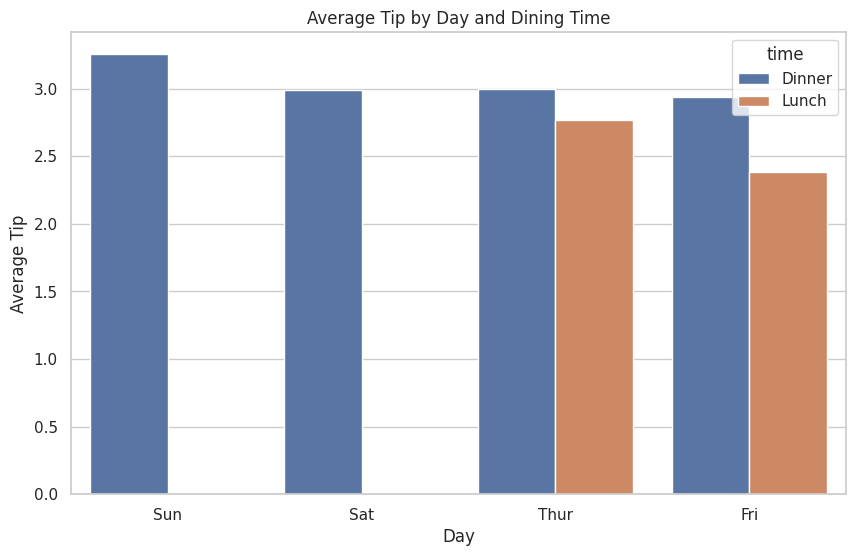

In [141]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='day',
    y='tip',
    hue='time',
    errorbar=None
)

plt.title('Average Tip by Day and Dining Time')
plt.xlabel('Day')
plt.ylabel('Average Tip')
plt.show()

In [142]:
pd.crosstab(df['day'], df['time'])

time,Dinner,Lunch
day,,
Fri,12,7
Sat,87,0
Sun,76,0
Thur,1,61


### Data Limitation — Dining Period Distribution

The distribution of dining periods varies substantially across days.

No lunch transactions are recorded on Saturday and Sunday, while Thursday observations are predominantly lunch transactions.

Consequently, comparisons between dining periods across all days may be affected by the uneven distribution of observations.


# **06 — Machine Learning**

### Objective

The objective is to predict the tip amount (`tip`) based on transaction characteristics and customer-related variables.

This is a **supervised regression problem**, because the target variable is continuous.

**Target variable:** `tip`

**Predictor variables:**
- `total_bill`
- `size`
- `sex`
- `smoker`
- `day`
- `time`

Three regression models are evaluated:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor



In [143]:
feature_cols = [
    'total_bill',
    'size',
    'sex',
    'smoker',
    'day',
    'time'
]

X = df[feature_cols]
y = df['tip']

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (244, 6)
y shape: (244,)


In [144]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print('Training set:', X_train.shape)
print('Testing set:', X_test.shape)

Training set: (195, 6)
Testing set: (49, 6)


In [145]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_features = ['total_bill', 'size']

categorical_features = [
    'sex',
    'smoker',
    'day',
    'time'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [146]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

## 6.2 Model Evaluation

In [147]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='MAE',
    ascending=True
)

print(results_df.round(3))

               Model    MAE   RMSE     R2
0  Linear Regression  0.667  0.839  0.437
1      Decision Tree  0.697  0.883  0.376
2      Random Forest  0.769  0.967  0.251


### Model Comparison

Linear Regression achieved the best performance, with the lowest MAE (0.667) and RMSE (0.839), and the highest R² (0.437).

The results suggest that the relationship between the selected predictors and tip amount can be captured reasonably well by a linear model.

Although Decision Tree and Random Forest can capture nonlinear relationships, they did not improve predictive performance on the test dataset.

Overall, Linear Regression is selected as the best-performing model among the three evaluated models.

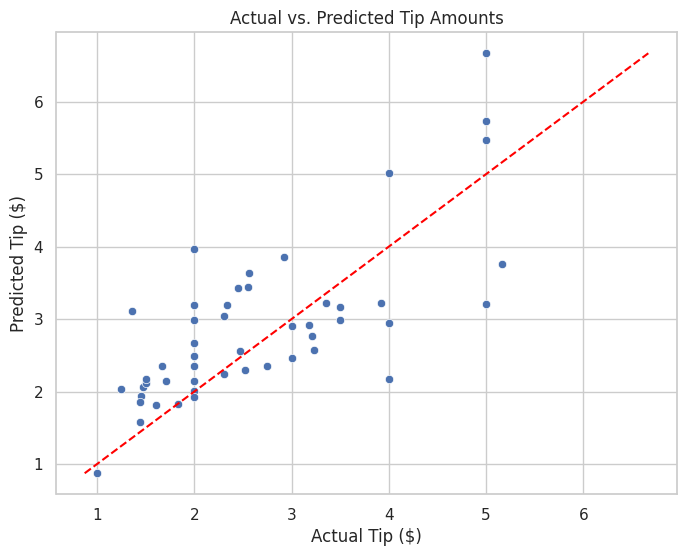

In [148]:


best_model = trained_models['Linear Regression']

y_pred = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--', color ='red'
)

plt.xlabel('Actual Tip ($)')
plt.ylabel('Predicted Tip ($)')
plt.title('Actual vs. Predicted Tip Amounts')

plt.show()

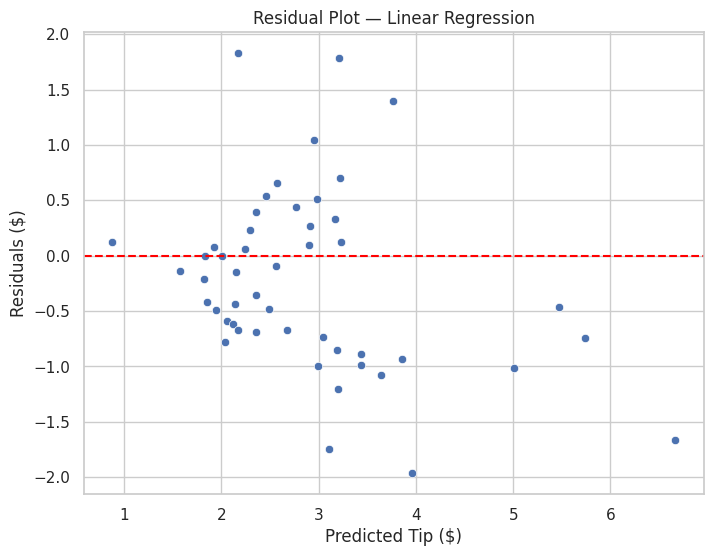

In [149]:
#Residual Analysis
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_pred,
    y=residuals
)

plt.axhline(
    y=0,
    linestyle='--', color = 'red'
)

plt.xlabel('Predicted Tip ($)')
plt.ylabel('Residuals ($)')
plt.title('Residual Plot — Linear Regression')

plt.show()

### Model Diagnostics

The Actual vs. Predicted plot indicates that Linear Regression captures the general relationship between the predictors and tip amounts. However, prediction errors become more noticeable for some larger tip values.

The residual plot shows that residuals are not entirely randomly distributed around zero. Several negative residuals appear at higher predicted values, suggesting that the model tends to overestimate some larger tips.

These diagnostic plots indicate that Linear Regression provides a reasonable baseline model, but its predictive performance could be improved by exploring additional variables or alternative model specifications.

In [150]:
#feature importance
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring='neg_mean_absolute_error'
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean,
    'Std': importance.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.round(4))

      Feature  Importance     Std
0  total_bill      0.4123  0.0684
4         day      0.0040  0.0084
5        time      0.0005  0.0068
2         sex     -0.0006  0.0019
3      smoker     -0.0076  0.0123
1        size     -0.0176  0.0243


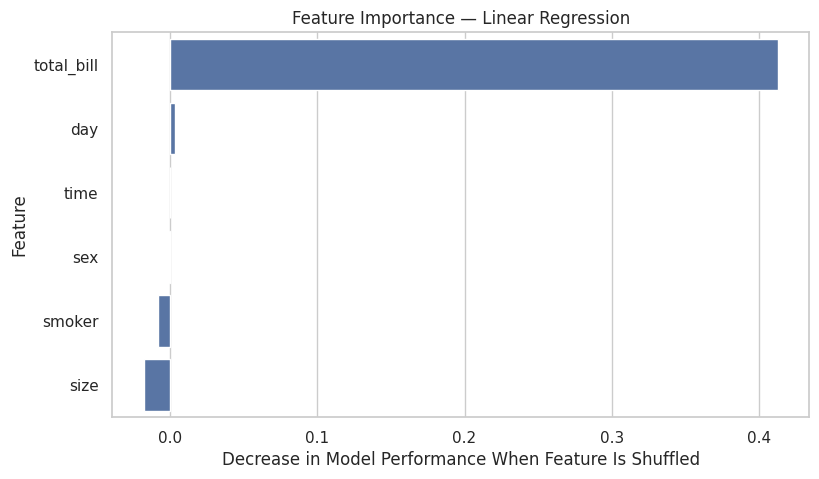

In [151]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance — Linear Regression')
plt.xlabel('Decrease in Model Performance When Feature Is Shuffled')
plt.ylabel('Feature')

plt.show()

### Feature Importance Analysis

Permutation importance indicates that `total_bill` is the dominant predictor of tip amount, with an importance score of 0.4123.

The remaining variables (`day`, `time`, `sex`, `smoker`, and `size`) show very small or negative importance scores on the test dataset.

This suggests that the total bill amount provides substantially more predictive information than the other selected variables in the Linear Regression model.

However, these results measure predictive contribution rather than causality. The relatively small test sample also means that the importance estimates should be interpreted with caution.

## Conclusion and Key Findings

### 1. Exploratory Data Analysis

- The average total bill was approximately $19.79.
- The average tip was approximately $3.00.
- Total bill and tip amount showed a positive relationship.
- Dinner transactions represented the majority of observations.
- The dataset contained no missing values, although one exact duplicate row was identified.

### 2. Statistical Analysis

- Pearson correlation showed a statistically significant positive relationship between total bill and tip amount (r = 0.676, p < 0.001).
- Tip amounts did not differ significantly between smokers and non-smokers based on the Welch t-test (p = 0.927).
- ANOVA did not find statistically significant differences in mean tips across days (p = 0.174).
- Kruskal-Wallis detected differences in tip distributions across days (p = 0.036). Further post-hoc analysis would be required to identify which days differ.

### 3. Machine Learning

Three regression models were evaluated:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor

Linear Regression achieved the best test performance, with an MAE of 0.667 and an R² of 0.437.

Permutation importance identified `total_bill` as the dominant predictor of tip amount.

### 4. Limitations

- The dataset contains only 244 observations.
- The analysis is based on a single restaurant tips dataset.
- The dataset does not include customer income, service quality, customer satisfaction, or other potentially relevant factors.
- The test sample is relatively small, so model performance estimates may vary across different data splits.
- The findings describe associations and predictive relationships, not causal effects.

### 5. Overall Conclusion

The analysis identifies a clear positive relationship between total bill amount and tip amount. Among the evaluated regression models, Linear Regression provided the strongest predictive performance.

Overall, the project demonstrates the application of data cleaning, exploratory data analysis, statistical hypothesis testing, regression modeling, model evaluation, and feature importance analysis to a real-world-style dataset.